In [1]:
# Importing libraies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
RANDOM_STATE = 42
TARGET_COL = "Listening_Time_minutes"
ID_COLS = ["id", "ID", "Id"]
sns.set_style("whitegrid")


In [2]:
# Data Loading
DATA_PATH = "train.csv"
df = pd.read_csv(DATA_PATH)

In [3]:
df.shape

(750000, 12)

In [4]:
df.head()

,id,Podcast_Name,Episode_Title,Episode_Length_minutes,Genre,Host_Popularity_percentage,Publication_Day,Publication_Time,Guest_Popularity_percentage,Number_of_Ads,Episode_Sentiment,Listening_Time_minutes
0,0,Mystery Matters,Episode 98,NaN,True Crime,74.81,Thursday,Night,NaN,0.0,Positive,31.41998
1,1,Joke Junction,Episode 26,119.80,Comedy,66.95,Saturday,Afternoon,75.95,2.0,Negative,88.01241
2,2,Study Sessions,Episode 16,73.90,Education,69.97,Tuesday,Evening,8.97,0.0,Negative,44.92531
3,3,Digital Digest,Episode 45,67.17,Technology,57.22,Monday,Morning,78.70,2.0,Positive,46.27824
4,4,Mind & Body,Episode 86,110.51,Health,80.07,Monday,Afternoon,58.68,3.0,Neutral,75.61031


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           750000 non-null  int64  
 1   Podcast_Name                 750000 non-null  object 
 2   Episode_Title                750000 non-null  object 
 3   Episode_Length_minutes       662907 non-null  float64
 4   Genre                        750000 non-null  object 
 5   Host_Popularity_percentage   750000 non-null  float64
 6   Publication_Day              750000 non-null  object 
 7   Publication_Time             750000 non-null  object 
 8   Guest_Popularity_percentage  603970 non-null  float64
 9   Number_of_Ads                749999 non-null  float64
 10  Episode_Sentiment            750000 non-null  object 
 11  Listening_Time_minutes       750000 non-null  float64
dtypes: float64(5), int64(1), object(6)
memory usage: 68.7+ MB


In [6]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)


Guest_Popularity_percentage    146030
Episode_Length_minutes          87093
Number_of_Ads                       1
dtype: int64

In [7]:
# Data Cleaning
def clean_data(df):
    df = df.copy()
    df = df.drop(columns=[c for c in ID_COLS if c in df.columns])
    df = df.drop_duplicates()
    for col in df.select_dtypes(include=[np.number]).columns:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].median())
    for col in df.select_dtypes(include=["object"]).columns:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].mode().iloc[0])
    return df

df = clean_data(df)


In [8]:
df.isna().sum().sum()

np.int64(0)

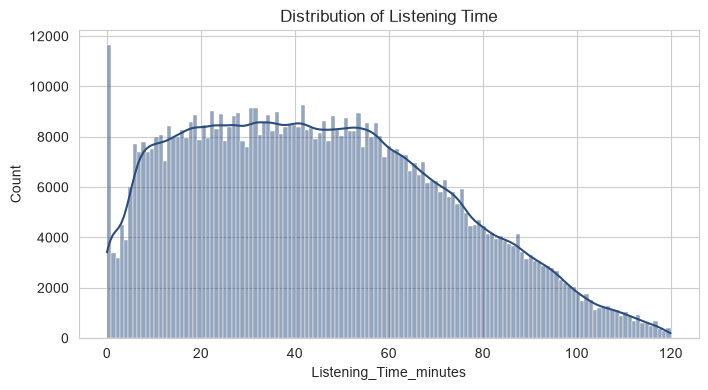

In [9]:
#Visulaization
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df[TARGET_COL], kde=True, color="#2B4C7E", ax=ax)
ax.set_title("Distribution of Listening Time")
plt.show()

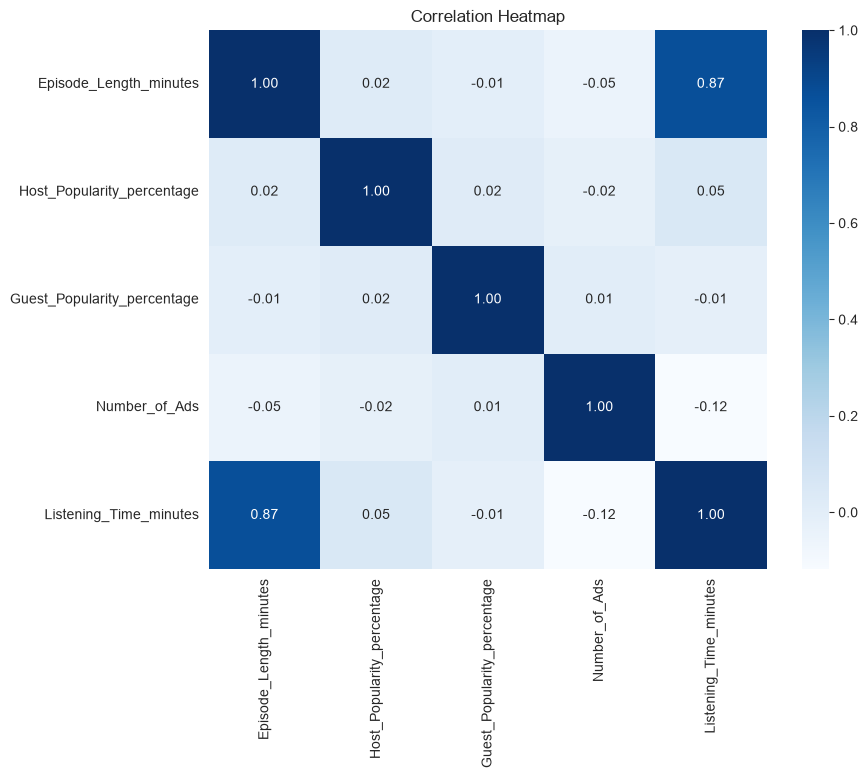

In [10]:
numeric_df = df.select_dtypes(include=[np.number])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Correlation Heatmap")
plt.show()

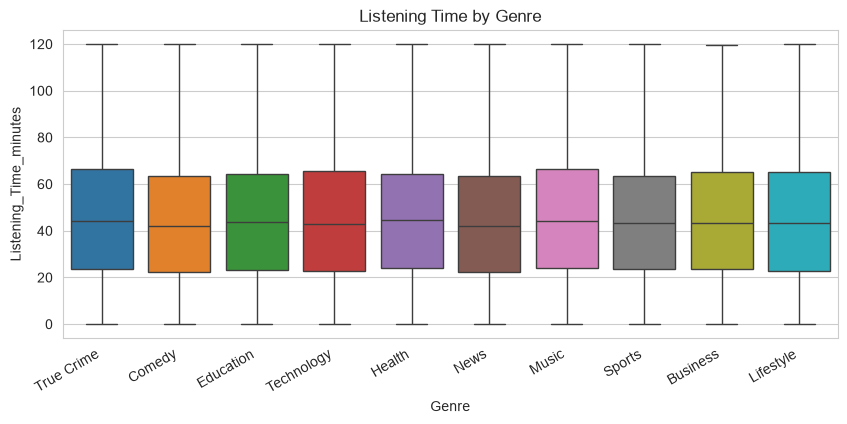

In [11]:
if "Genre" in df.columns:
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(data=df, x="Genre", y=TARGET_COL, ax=ax, hue="Genre", legend=False)
    plt.xticks(rotation=30, ha="right")
    ax.set_title("Listening Time by Genre")
    plt.show()


In [12]:
# Feature Engineering
def engineer_features(df):
    df = df.copy()
    if "Number_of_Ads" in df.columns and "Episode_Length_minutes" in df.columns:
        df["Ads_per_minute"] = df["Number_of_Ads"] / df["Episode_Length_minutes"].replace(0, np.nan)
        df["Ads_per_minute"] = df["Ads_per_minute"].fillna(0)
    if "Publication_Day" in df.columns:
        df["Is_Weekend"] = df["Publication_Day"].isin(["Saturday", "Sunday"]).astype(int)
    if "Host_Popularity_percentage" in df.columns and "Guest_Popularity_percentage" in df.columns:
        df["Popularity_Gap"] = df["Host_Popularity_percentage"] - df["Guest_Popularity_percentage"]
    return df
df = engineer_features(df)
df.columns.tolist()

['Podcast_Name',
 'Episode_Title',
 'Episode_Length_minutes',
 'Genre',
 'Host_Popularity_percentage',
 'Publication_Day',
 'Publication_Time',
 'Guest_Popularity_percentage',
 'Number_of_Ads',
 'Episode_Sentiment',
 'Listening_Time_minutes',
 'Ads_per_minute',
 'Is_Weekend',
 'Popularity_Gap']

In [13]:
#Using Hugging Face Sentiment feature
USE_HF_SENTIMENT = True

def score_sentiment_dedup(df, text_col="Episode_Title"):
    import torch
    from transformers import pipeline

    device = 0 if torch.cuda.is_available() else -1
    print(f"Using {'GPU: ' + torch.cuda.get_device_name(0) if device == 0 else 'CPU'}")

    clf = pipeline(
        "sentiment-analysis",
        model="distilbert-base-uncased-finetuned-sst-2-english",
        device=device,
    )
    texts = df[text_col].fillna("").astype(str)
    unique_texts = texts.unique().tolist()
    print(f"Total rows: {len(df):,}  |  Unique {text_col} values: {len(unique_texts):,}")

    results = clf(unique_texts, truncation=True, batch_size=32)
    sentiment_map = {
        t: (r["score"] if r["label"] == "POSITIVE" else -r["score"])
        for t, r in zip(unique_texts, results)
    }
    return texts.map(sentiment_map)


if USE_HF_SENTIMENT and "Episode_Title" in df.columns:
    try:
        df["HF_Sentiment_Score"] = score_sentiment_dedup(df, "Episode_Title")
        print("\nHugging Face sentiment feature added.")
        print(df[["Episode_Title", "HF_Sentiment_Score"]].head())
    except Exception as e:
        print(f"Skipping HF sentiment (reason: {e})")
        USE_HF_SENTIMENT = False
else:
    USE_HF_SENTIMENT = False

Using GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


Device set to use cuda:0


Total rows: 750,000  |  Unique Episode_Title values: 100

Hugging Face sentiment feature added.
  Episode_Title  HF_Sentiment_Score
0    Episode 98            0.985908
1    Episode 26            0.983879
2    Episode 16            0.985062
3    Episode 45            0.968616
4    Episode 86            0.982368


In [14]:
#Encoding
def encode_features(df, target_col=TARGET_COL):
    df = df.copy()
    drop_cols = [c for c in ["Episode_Title"] if c in df.columns]
    df = df.drop(columns=drop_cols)
    y = df[target_col]
    X = df.drop(columns=[target_col])
    encoders = {}
    for col in X.select_dtypes(include=["object"]).columns:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        encoders[col] = le
    return X, y, encoders

In [15]:
#Split
X, y, encoders = encode_features(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

In [16]:
#Scaling
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print(f"Train: {X_train_s.shape}, Test: {X_test_s.shape}")

Train: (600000, 13), Test: (150000, 13)


## 9. Train & Compare All Three Models

**Note on scale:** on the full 750,000-row dataset, Random Forest with
`n_jobs=-1` typically finishes in well under a minute on a modern
multi-core machine. `HistGradientBoostingRegressor` is built
specifically for large tabular datasets and is typically *faster*
than plain `GradientBoostingRegressor` even on smaller data. If any
model still feels too slow on your machine, reduce `n_estimators` or
`max_iter` below — the code will still run correctly with lower values,
just with slightly less accuracy.


In [17]:
#Model Training
MODEL_REGISTRY = {
    "Linear Regression": lambda: LinearRegression(),
    "Random Forest Regressor": lambda: RandomForestRegressor(
        n_estimators=150, max_depth=14, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting (Histogram-based)": lambda: HistGradientBoostingRegressor(
        max_iter=200, max_depth=8, learning_rate=0.08, random_state=RANDOM_STATE
    ),
}

In [18]:
def train_and_evaluate(model_name, X_train, X_test, y_train, y_test):
    model = MODEL_REGISTRY[model_name]()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    metrics = {
        "RMSE": float(np.sqrt(mean_squared_error(y_test, preds))),
        "MAE": float(mean_absolute_error(y_test, preds)),
        "R2": float(r2_score(y_test, preds)),
    }
    return model, metrics, preds

In [19]:
results = {}
for name in MODEL_REGISTRY:
    print(f"Training {name}...")
    model, metrics, preds = train_and_evaluate(name, X_train_s, X_test_s, y_train, y_test)
    results[name] = {"model": model, "metrics": metrics, "preds": preds}
    print(f"  RMSE={metrics['RMSE']:.2f}  MAE={metrics['MAE']:.2f}  R2={metrics['R2']:.3f}\n")

Training Linear Regression...
  RMSE=13.34  MAE=9.76  R2=0.758

Training Random Forest Regressor...
  RMSE=12.97  MAE=9.41  R2=0.771

Training Gradient Boosting (Histogram-based)...
  RMSE=13.05  MAE=9.51  R2=0.768



In [20]:
metrics_df = pd.DataFrame({name: r["metrics"] for name, r in results.items()}).T.sort_values("RMSE")
metrics_df.style.format({"RMSE": "{:.2f}", "MAE": "{:.2f}", "R2": "{:.3f}"}).highlight_min(
    subset=["RMSE", "MAE"], color="#c8e6c9"
).highlight_max(subset=["R2"], color="#c8e6c9")


,RMSE,MAE,R2
Random Forest Regressor,12.97,9.41,0.771
Gradient Boosting (Histogram-based),13.05,9.51,0.768
Linear Regression,13.34,9.76,0.758


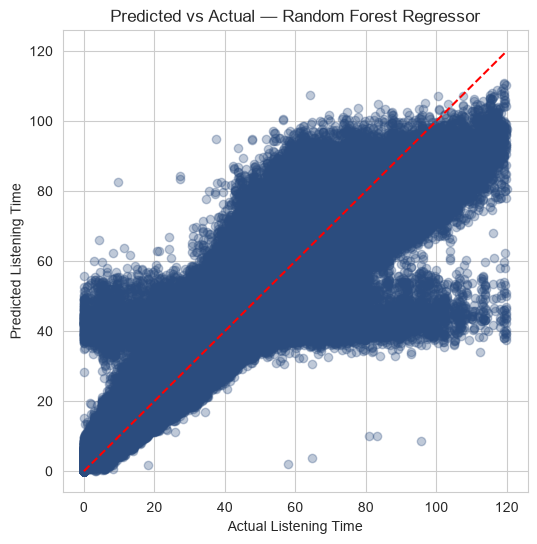

Best model by RMSE: Random Forest Regressor


In [21]:
best_model_name = metrics_df.index[0]
best_preds = results[best_model_name]["preds"]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_preds, alpha=0.3, color="#2B4C7E")
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "r--")
ax.set_xlabel("Actual Listening Time")
ax.set_ylabel("Predicted Listening Time")
ax.set_title(f"Predicted vs Actual — {best_model_name}")
plt.show()

print(f"Best model by RMSE: {best_model_name}")

## 10. Feature Importance — Answers RQ1

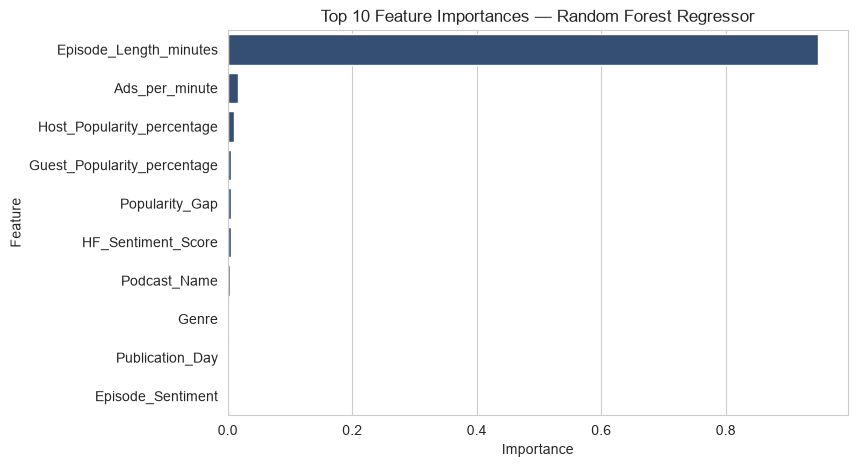

,Feature,Importance
0,Episode_Length_minutes,0.948462
1,Ads_per_minute,0.016869
2,Host_Popularity_percentage,0.009748
3,Guest_Popularity_percentage,0.005608
4,Popularity_Gap,0.004669
5,HF_Sentiment_Score,0.004514
6,Podcast_Name,0.003342
7,Genre,0.001907
8,Publication_Day,0.001878
9,Episode_Sentiment,0.001295


In [22]:
#Feature Importance
def get_feature_importance(model, feature_names):
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
    elif hasattr(model, "coef_"):
        importances = np.abs(model.coef_)
    else:
        return pd.DataFrame(columns=["Feature", "Importance"])
    return pd.DataFrame({"Feature": feature_names, "Importance": importances}) \
             .sort_values("Importance", ascending=False).reset_index(drop=True)

imp_df = get_feature_importance(results[best_model_name]["model"], list(X.columns))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=imp_df.head(10), x="Importance", y="Feature", ax=ax, color="#2B4C7E")
ax.set_title(f"Top 10 Feature Importances — {best_model_name}")
plt.show()
imp_df


## 11. Ablation Study — Metadata vs. Metadata + Content (Answers RQ4)

In [23]:
#Metadata vs. Metadata + Content
def run_ablation(X, y, feature_subset, label):
    Xs = X[feature_subset]
    X_tr, X_te, y_tr, y_te = train_test_split(Xs, y, test_size=0.2, random_state=RANDOM_STATE)
    sc = StandardScaler()
    X_tr_s = pd.DataFrame(sc.fit_transform(X_tr), columns=Xs.columns)
    X_te_s = pd.DataFrame(sc.transform(X_te), columns=Xs.columns)

    model = RandomForestRegressor(n_estimators=150, max_depth=14, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(X_tr_s, y_tr)
    preds = model.predict(X_te_s)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2 = r2_score(y_te, preds)
    print(f"{label:35s} RMSE={rmse:.2f}  R2={r2:.3f}")
    return rmse, r2

metadata_cols = [c for c in X.columns if c != "HF_Sentiment_Score"]
all_cols = list(X.columns)

print("--- Ablation: Metadata-only vs Metadata+Content ---")
run_ablation(X, y, metadata_cols, "Metadata only")
if "HF_Sentiment_Score" in X.columns:
    run_ablation(X, y, all_cols, "Metadata + HF Content Feature")
else:
    print("(HF_Sentiment_Score not present — enable USE_HF_SENTIMENT above)")


--- Ablation: Metadata-only vs Metadata+Content ---
Metadata only                       RMSE=12.98  R2=0.771
Metadata + HF Content Feature       RMSE=12.97  R2=0.771


## 12. Genre-wise Performance (Answers RQ5)

,Mean Absolute Error,N (test rows)
Genre,,
Sports,9.228399,17431
Comedy,9.229609,16156
Lifestyle,9.319677,16681
True Crime,9.348437,17001
Technology,9.471435,17435
Business,9.490867,16019
News,9.506487,12658
Health,9.512577,14198
Education,9.526954,9930


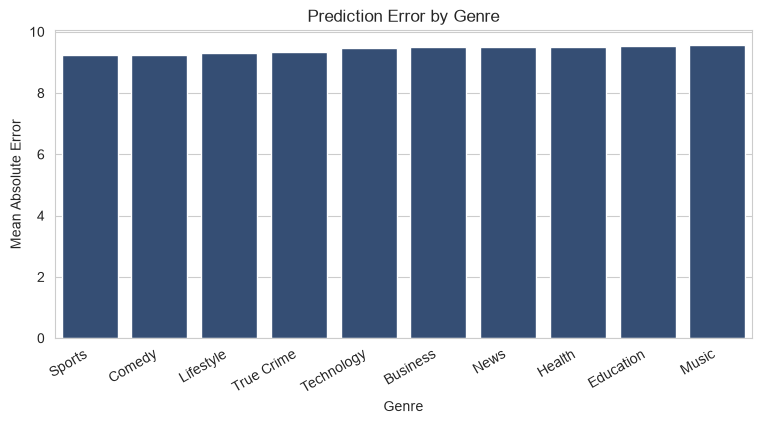

In [24]:
#Genre-wise Performance
if "Genre" in encoders:
    genre_encoder = encoders["Genre"]
    test_genres = genre_encoder.inverse_transform(X_test["Genre"])

    genre_results = pd.DataFrame({
        "Genre": test_genres,
        "Actual": y_test.values,
        "Predicted": best_preds,
    })
    genre_results["AbsError"] = (genre_results["Actual"] - genre_results["Predicted"]).abs()

    genre_summary = genre_results.groupby("Genre")["AbsError"].agg(["mean", "count"]).sort_values("mean")
    genre_summary.columns = ["Mean Absolute Error", "N (test rows)"]
    display(genre_summary)

    fig, ax = plt.subplots(figsize=(9, 4))
    sns.barplot(data=genre_summary.reset_index(), x="Genre", y="Mean Absolute Error", ax=ax, color="#2B4C7E")
    plt.xticks(rotation=30, ha="right")
    ax.set_title("Prediction Error by Genre")
    plt.show()
else:
    print("No Genre column found.")


## 13. Popularity Bias Check (Answers RQ6)

In [25]:
#Popularity Bias Check
host_features = [c for c in imp_df["Feature"] if "Popularity" in c or "Host" in c]
host_importance_share = imp_df[imp_df["Feature"].isin(host_features)]["Importance"].sum()
total_importance = imp_df["Importance"].sum()

print(f"Share of total feature importance held by host/guest-popularity features: "
      f"{host_importance_share / total_importance:.1%}")

if host_importance_share / total_importance > 0.5:
    print("Over half the model's decision-making rests on host/guest popularity alone —")
    print("this suggests possible popularity bias (Gap 4 / RQ6).")
else:
    print("Host/guest popularity does not dominate — other episode-specific features")
    print("meaningfully contribute to the prediction.")


Share of total feature importance held by host/guest-popularity features: 2.0%
Host/guest popularity does not dominate — other episode-specific features
meaningfully contribute to the prediction.
